# Clasificación de residuos mediante una Red Neuronal Convolucional (CNN)

## Objetivo del proyecto

Desarrollar un modelo de Deep Learning basado en una Red Neuronal Convolucional capaz de clasificar imágenes de residuos en diferentes categorías.

## Dataset

Se utilizará un conjunto de imágenes de residuos clasificados en seis categorías:

- Cartón
- Vidrio
- Metal
- Papel
- Plástico
- Basura

El modelo será entrenado utilizando técnicas de preprocesamiento, normalización y Data Augmentation.

In [1]:
# Importación de librerías principales

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import pathlib

print("TensorFlow versión:", tf.__version__)

TensorFlow versión: 2.21.0


In [5]:
# Verificar GPU disponible

device = tf.config.list_physical_devices('GPU')

if device:
    print("GPU disponible:")
    print(device)
else:
    print("No hay GPU disponible")

GPU disponible:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
# Descargar dataset de residuos

!pip install -q kagglehub

import kagglehub

path = kagglehub.dataset_download(
    "asdasdasasdas/garbage-classification"
)

print("Dataset descargado en:")
print(path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset descargado en:
/kaggle/input/garbage-classification


In [9]:
import os

for carpeta, subcarpetas, archivos in os.walk(path):
    print(carpeta)
    break

/kaggle/input/garbage-classification


In [10]:
import os

# Mostrar estructura del dataset

for carpeta, subcarpetas, archivos in os.walk(path):
    print("Carpeta encontrada:")
    print(carpeta)
    print("Número de archivos:", len(archivos))
    print("-----------------------")

Carpeta encontrada:
/kaggle/input/garbage-classification
Número de archivos: 5
-----------------------
Carpeta encontrada:
/kaggle/input/garbage-classification/Garbage classification
Número de archivos: 0
-----------------------
Carpeta encontrada:
/kaggle/input/garbage-classification/Garbage classification/Garbage classification
Número de archivos: 0
-----------------------
Carpeta encontrada:
/kaggle/input/garbage-classification/Garbage classification/Garbage classification/metal
Número de archivos: 410
-----------------------
Carpeta encontrada:
/kaggle/input/garbage-classification/Garbage classification/Garbage classification/glass
Número de archivos: 501
-----------------------
Carpeta encontrada:
/kaggle/input/garbage-classification/Garbage classification/Garbage classification/paper
Número de archivos: 594
-----------------------
Carpeta encontrada:
/kaggle/input/garbage-classification/Garbage classification/Garbage classification/trash
Número de archivos: 137
------------------

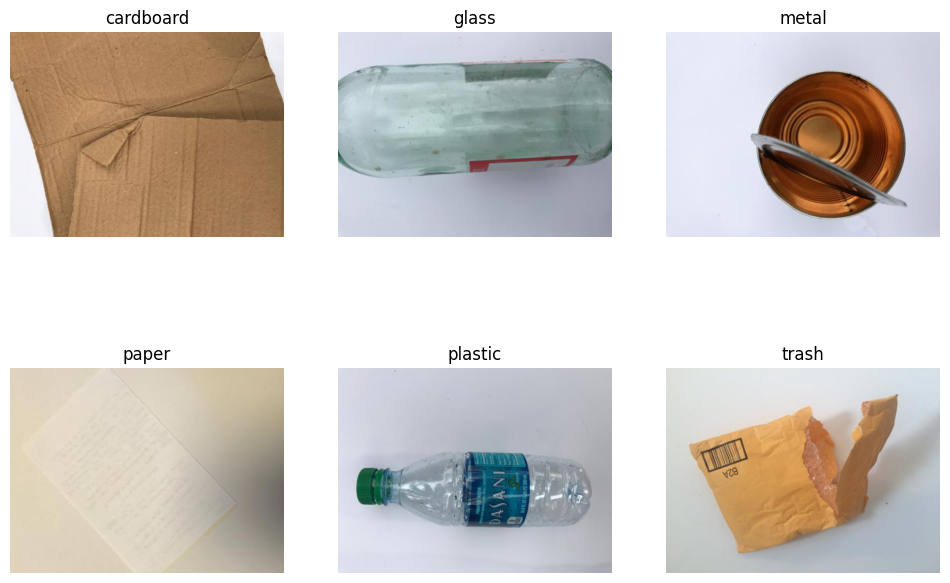

In [11]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os


# Ruta donde están las clases
data_dir = os.path.join(
    path,
    "Garbage classification",
    "Garbage classification"
)


# Nombres de las clases
class_names = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]


plt.figure(figsize=(12,8))


for i, clase in enumerate(class_names):

    carpeta = os.path.join(data_dir, clase)

    imagen = random.choice(os.listdir(carpeta))

    ruta_imagen = os.path.join(carpeta, imagen)

    img = mpimg.imread(ruta_imagen)

    plt.subplot(2,3,i+1)

    plt.imshow(img)

    plt.title(clase)

    plt.axis("off")


plt.show()

In [12]:
import tensorflow as tf

# Tamaño de imágenes
IMG_SIZE = (224,224)

# Tamaño de lote
BATCH_SIZE = 32


# Dataset de entrenamiento (70%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


# Dataset temporal validación + prueba (30%)
temp_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


print("Dataset cargado correctamente")


Found 2527 files belonging to 6 classes.
Using 1769 files for training.
Found 2527 files belonging to 6 classes.
Using 758 files for validation.
Dataset cargado correctamente


In [14]:
# Separar validación y prueba

val_batches = tf.data.experimental.cardinality(temp_ds)

test_ds = temp_ds.take(val_batches // 3)

val_ds = temp_ds.skip(val_batches // 3)


print("Validación preparada")
print("Prueba preparada")

Validación preparada
Prueba preparada


In [15]:
AUTOTUNE = tf.data.AUTOTUNE


train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)

val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)


print("Datos optimizados")

Datos optimizados


In [16]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

print("Normalización creada")

Normalización creada


In [17]:
# Data Augmentation

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.2),

    tf.keras.layers.RandomZoom(0.2),

    tf.keras.layers.RandomContrast(0.2)

])


print("Data Augmentation creado")

Data Augmentation creado


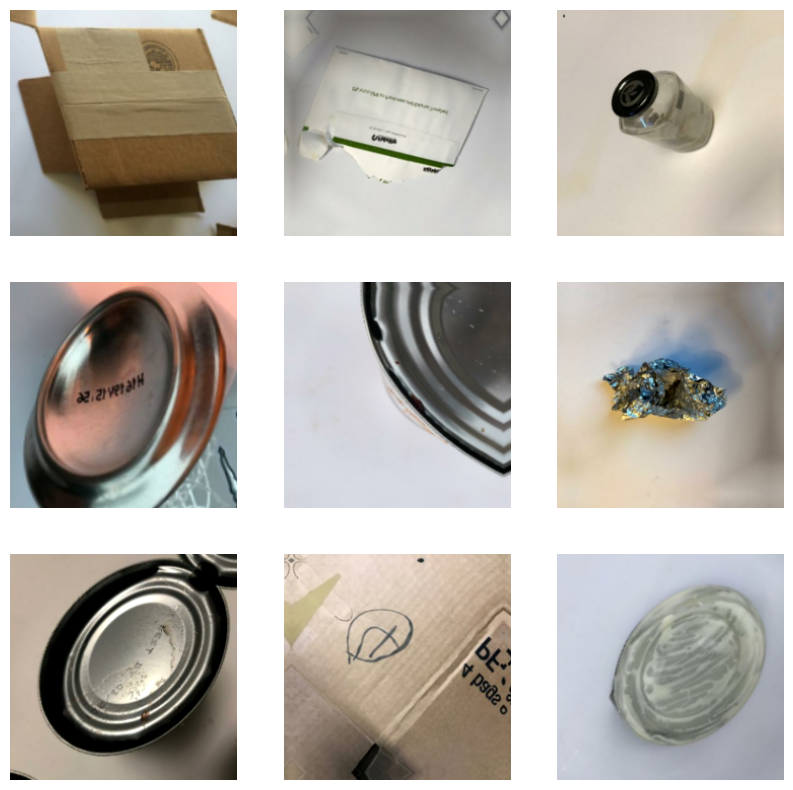

In [18]:
# Mostrar ejemplos con Data Augmentation

import matplotlib.pyplot as plt


for images, labels in train_ds.take(1):

    plt.figure(figsize=(10,10))

    for i in range(9):

        augmented_image = data_augmentation(images[i])

        plt.subplot(3,3,i+1)

        plt.imshow(augmented_image.numpy().astype("uint8"))

        plt.axis("off")


    plt.show()

In [19]:
tf.keras.backend.clear_session()

print("Memoria del modelo limpiada")

Memoria del modelo limpiada


In [20]:
import tensorflow as tf

tf.keras.backend.clear_session()

print("Sesión limpia")

Sesión limpia


In [21]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

print("Normalización nueva creada")

Normalización nueva creada


In [22]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.2),

    tf.keras.layers.RandomZoom(0.2),

    tf.keras.layers.RandomContrast(0.2)

])

print("Data Augmentation nuevo creado")

Data Augmentation nuevo creado


In [23]:
num_classes = len(class_names)

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(224,224,3)),

    data_augmentation,

    normalization_layer,

    tf.keras.layers.Conv2D(
        32,
        (3,3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(),


    tf.keras.layers.Conv2D(
        64,
        (3,3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(),


    tf.keras.layers.Conv2D(
        128,
        (3,3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(),


    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )

])


print("CNN creada correctamente")

CNN creada correctamente


In [24]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Compilación del modelo

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


print("Modelo compilado correctamente")

Modelo compilado correctamente


In [26]:
# Entrenamiento del modelo CNN

epochs = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - accuracy: 0.2606 - loss: 1.8001 - val_accuracy: 0.3008 - val_loss: 1.6030
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.3827 - loss: 1.4900 - val_accuracy: 0.4004 - val_loss: 1.4348
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.4370 - loss: 1.4190 - val_accuracy: 0.3865 - val_loss: 1.4043
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.4681 - loss: 1.3417 - val_accuracy: 0.4442 - val_loss: 1.3068
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.4811 - loss: 1.3265 - val_accuracy: 0.4442 - val_loss: 1.3557
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.4901 - loss: 1.3020 - val_accuracy: 0.4681 - val_loss: 1.2949
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.5037 - loss: 1.2528 - val_accuracy: 0.4203 - val_loss: 1.3842
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.5105 - loss: 1.2702 - val_accuracy: 0.4801 -

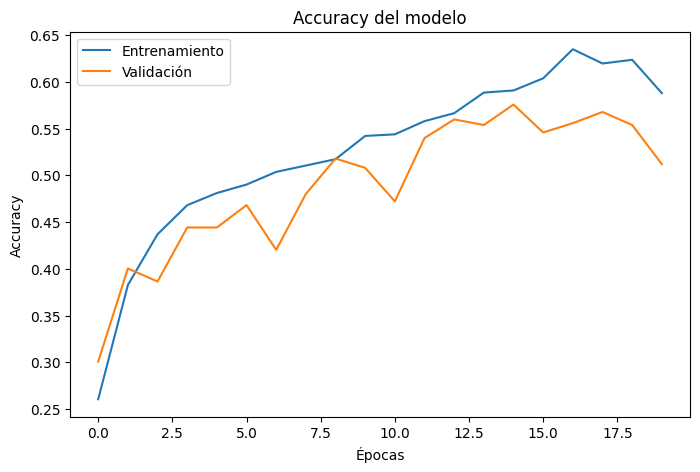

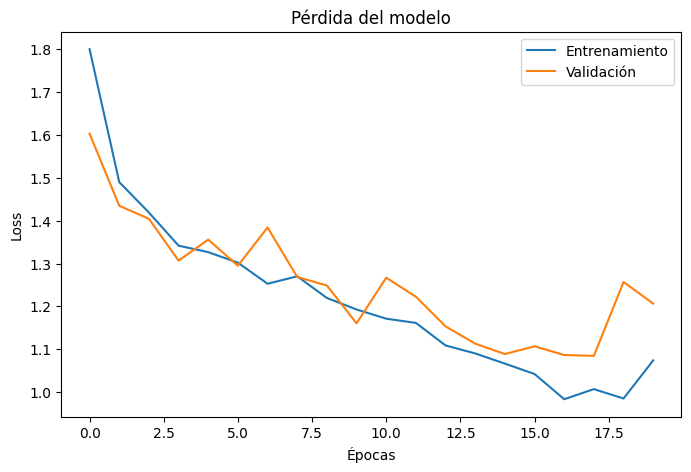

In [27]:
import matplotlib.pyplot as plt


# Accuracy

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Accuracy del modelo")

plt.xlabel("Épocas")

plt.ylabel("Accuracy")

plt.legend([
    "Entrenamiento",
    "Validación"
])

plt.show()


# Loss

plt.figure(figsize=(8,5))

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Pérdida del modelo")

plt.xlabel("Épocas")

plt.ylabel("Loss")

plt.legend([
    "Entrenamiento",
    "Validación"
])

plt.show()

In [28]:
# Evaluación con conjunto de prueba

test_loss, test_accuracy = model.evaluate(test_ds)

print("Precisión en prueba:", test_accuracy)
print("Pérdida en prueba:", test_loss)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5312 - loss: 1.2465
Precisión en prueba: 0.53125
Pérdida en prueba: 1.2465204000473022


In [29]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix


# Obtener etiquetas reales y predicciones

y_true = []
y_pred = []


for images, labels in test_ds:

    predictions = model.predict(images)

    y_true.extend(labels.numpy())

    y_pred.extend(
        np.argmax(predictions, axis=1)
    )


y_true = np.array(y_true)
y_pred = np.array(y_pred)


print("Predicciones generadas")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Predicciones generadas


In [30]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

   cardboard       0.93      0.60      0.73        43
       glass       0.70      0.28      0.40        50
       metal       0.51      0.66      0.57        44
       paper       0.39      0.66      0.49        50
     plastic       0.53      0.62      0.57        48
       trash       0.44      0.19      0.27        21

    accuracy                           0.53       256
   macro avg       0.58      0.50      0.51       256
weighted avg       0.59      0.53      0.52       256



El modelo CNN alcanzó una precisión global del 53% sobre el conjunto de prueba compuesto por 256 imágenes. La clase con mejor desempeño fue "cardboard", alcanzando un precision de 93% y un F1-score de 73%, indicando una buena capacidad para identificar esta categoría. Las clases glass y trash presentaron menor rendimiento debido posiblemente a la similitud visual con otras categorías y al menor número de imágenes disponibles para entrenamiento. En general, la red logró aprender características visuales relevantes, aunque existe oportunidad de mejora mediante arquitecturas más avanzadas como Transfer Learning.

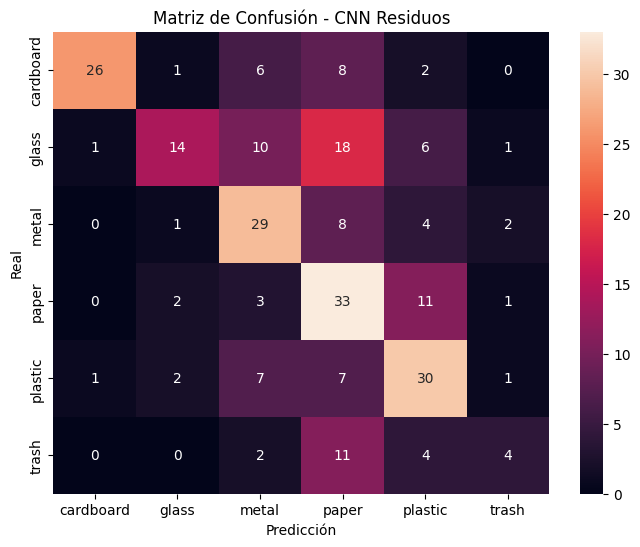

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt


cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(figsize=(8,6))


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel("Predicción")

plt.ylabel("Real")

plt.title("Matriz de Confusión - CNN Residuos")


plt.show()

La matriz de confusión evidencia que el modelo presenta un mejor desempeño en categorías con características visuales más diferenciadas como cardboard, metal y paper. Las mayores dificultades se encuentran en trash y glass debido a la similitud visual entre residuos y al menor número de muestras disponibles. Estos resultados sugieren que una arquitectura basada en transferencia de aprendizaje podría mejorar la capacidad de extracción de características.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


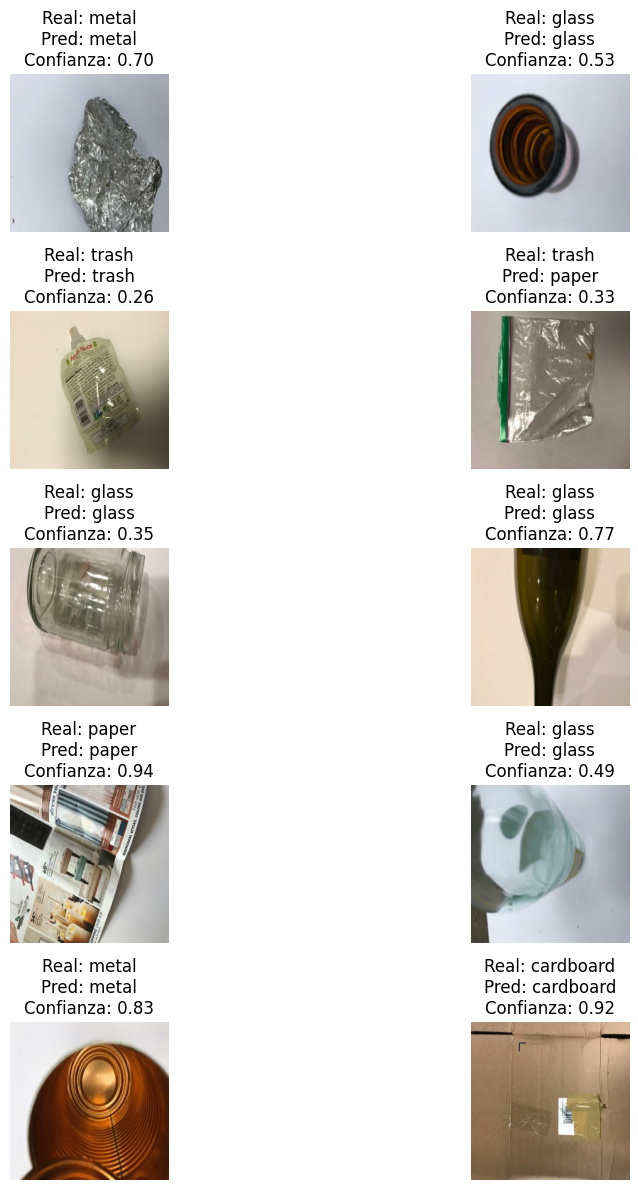

In [32]:
import matplotlib.pyplot as plt
import numpy as np


plt.figure(figsize=(12,12))


contador = 0


for images, labels in test_ds.take(1):

    predictions = model.predict(images)


    for i in range(10):

        contador += 1

        plt.subplot(5,2,contador)

        plt.imshow(images[i].numpy().astype("uint8"))


        pred_class = class_names[
            np.argmax(predictions[i])
        ]

        confidence = np.max(predictions[i])


        real_class = class_names[
            labels[i]
        ]


        plt.title(
            f"Real: {real_class}\n"
            f"Pred: {pred_class}\n"
            f"Confianza: {confidence:.2f}"
        )


        plt.axis("off")


plt.tight_layout()

plt.show()

In [33]:
# Guardar modelo entrenado

model.save(
    "modelo_residuos.keras"
)

print("Modelo guardado correctamente")

Modelo guardado correctamente


In [34]:
import os

print(
    os.path.getsize("modelo_residuos.keras") / (1024*1024),
    "MB"
)

127.88698863983154 MB
